In [50]:
import numpy as np
import matplotlib.pyplot as plt
from src.print_utils import print_kv, print_table_header, print_table_row,print_line

plt.style.use("styles/plots.mplstyle")

In [51]:
coeff_file_name = ["0","0_5","1","1_5","2","3","5"]
coeff_value = [0,0.5,1,1.5,2,3,5]

diffusion_time_0 = 0.728888
diffusion_time_0_inSample = 0.728888 / 5e-3


  $\Upsilon$    |   MSE border    |   MSE middle    | cut in samples 
----------------------------------------------------------------------
       Tikhonov |       2.737e+00 |       3.007e-05 |             218
              0 |       4.254e+00 |       2.127e-03 |               0
            0.5 |       5.378e+00 |       4.460e-06 |              72
              1 |       2.183e+00 |       1.448e-07 |             145
            1.5 |       1.958e+00 |       9.452e-08 |             218
              2 |       2.447e+00 |       3.940e-08 |             291
              3 |       2.737e+00 |       2.908e-08 |             437
              5 |       2.749e+00 |       2.150e-08 |             728


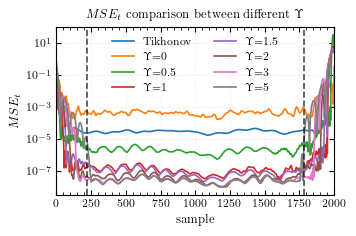

In [57]:
from cProfile import label

from matplotlib import figure


plt.figure()

ax = plt.gca()

i = 0

print_table_header([
                r"$\Upsilon$",
                "MSE border",
                "MSE middle",
                "cut in samples"
                ])
print_line()

#Tickonov

mse_t = np.loadtxt(f"./assets/tikhonov_learned/lru5_20/mse_t/mse_t_0.csv", delimiter=";")
mse_t = mse_t[1]
plt.plot(mse_t, label=rf"Tikhonov")

delta_t = int(diffusion_time_0_inSample * 1.5)

    
mse_middle = (np.sum(mse_t[delta_t:-delta_t-1]))/np.size(mse_t[delta_t:-delta_t-1])
mse_border = np.sum(mse_t[0:delta_t-1]) + np.sum(mse_t[-delta_t:-1])/(np.size(mse_t[0:delta_t-1]) + np.size(mse_t[-delta_t:-1]))

print_table_row([
                f"Tikhonov",
                f"{mse_border:.3e}",
                f"{mse_middle:.3e}",
                delta_t]
            )
    

for _ in range(np.size(coeff_file_name)):
    mse_t = np.loadtxt(f"./assets/tikhonov_learned/lru5_20/mse_t/mse_t_{coeff_file_name[i]}.csv", delimiter=";")
    mse_t = mse_t[0]
    plt.plot(mse_t, label=rf"$\Upsilon$={coeff_value[i]}")
    
    delta_t = int(diffusion_time_0_inSample * coeff_value[i])
    
    mse_middle = (np.sum(mse_t[delta_t:-delta_t-1]))/np.size(mse_t[delta_t:-delta_t-1])
    mse_border = np.sum(mse_t[0:delta_t-1]) + np.sum(mse_t[-delta_t:-1])/(np.size(mse_t[0:delta_t-1]) + np.size(mse_t[-delta_t:-1]))
    
    
    print_table_row([
                    f"{coeff_value[i]}",
                    f"{mse_border:.3e}",
                    f"{mse_middle:.3e}",
                    delta_t]
                )
    
    i = i + 1

ax.axvline(x= int(diffusion_time_0_inSample * 1.5), ls="--", c="k", alpha=0.7)
ax.axvline(x= np.size(mse_t)-int(diffusion_time_0_inSample * 1.5), ls="--", c="k", alpha=0.7)

plt.legend(ncols=2)
plt.grid()
plt.yscale("log")
plt.xlabel("sample")
plt.ylabel(r"$MSE_t$")
plt.title(r"$MSE_t$ comparison between different $\Upsilon$")
plt.minorticks_on()
plt.xlim([0,2000])

plt.savefig("assets/tikhonov_learned/lru5_20/mse_t/mse_t_comparisons.pdf", dpi=150, bbox_inches='tight')